In [1]:

print("Hello, Data Analyst!")


Hello, Data Analyst!


In [2]:
!pip install pandas

In [3]:
!pip install matplotlib

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
import pandas as pd
import kagglehub
import glob
import os

# 1. Download the full dataset folder
dataset_path = kagglehub.dataset_download("aamir28/student-sleep-screen-time-and-academic-performance")

# 2. Automatically find any CSV file inside that folder
csv_files = glob.glob(os.path.join(dataset_path, "*.csv"))

if csv_files:
    # 3. Load the first CSV file found
    df = pd.read_csv(csv_files[0])
    print("Successfully loaded:", os.path.basename(csv_files[0]))
    print(df.head())
else:
    print("No CSV files found in the dataset folder.")


Using Colab cache for faster access to the 'student-sleep-screen-time-and-academic-performance' dataset.
Successfully loaded: student_sleep_screen_time_academic_performance.csv
  student_id  age  gender  year_of_study   major_category  \
0    STU2001   21    Male              3       Humanities   
1    STU2002   20  Female              2             STEM   
2    STU2003   20    Male              4  Social Sciences   
3    STU2004   22       F              1       Humanities   
4    STU2005   23  Female              4  Social Sciences   

         residence_type    chronotype  avg_bedtime_hour  \
0           With Family    Early Bird              22.3   
1             Dormitory  Intermediate              23.1   
2           With Family  Intermediate              23.4   
3  Off-campus Apartment     Night Owl               0.9   
4  Off-campus Apartment    Early Bird              23.4   

   avg_sleep_hours_weekday  weekend_sleep_delta_hours  ...  naps_per_week  \
0                      7

In [12]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Correctly targets the exact filename verified inside the dataset repo
df = kagglehub.dataset_load(
    adapter=KaggleDatasetAdapter.PANDAS,
    handle="aamir28/student-sleep-screen-time-and-academic-performance",
    path="student_sleep_screen_time_academic_performance.csv"  # <-- Fixed filename
)

# Display the first few rows to verify it works
print(df.head())


Using Colab cache for faster access to the 'student-sleep-screen-time-and-academic-performance' dataset.
  student_id  age  gender  year_of_study   major_category  \
0    STU2001   21    Male              3       Humanities   
1    STU2002   20  Female              2             STEM   
2    STU2003   20    Male              4  Social Sciences   
3    STU2004   22       F              1       Humanities   
4    STU2005   23  Female              4  Social Sciences   

         residence_type    chronotype  avg_bedtime_hour  \
0           With Family    Early Bird              22.3   
1             Dormitory  Intermediate              23.1   
2           With Family  Intermediate              23.4   
3  Off-campus Apartment     Night Owl               0.9   
4  Off-campus Apartment    Early Bird              23.4   

   avg_sleep_hours_weekday  weekend_sleep_delta_hours  ...  naps_per_week  \
0                      7.6                        2.0  ...              0   
1                  

In [13]:
import pandas as pd

# Loads the dataset directly from the environment cache path
df = pd.read_csv('/kaggle/input/student-sleep-screen-time-and-academic-performance/student_sleep_screen_time_academic_performance.csv')
print(df.head())


  student_id  age  gender  year_of_study   major_category  \
0    STU2001   21    Male              3       Humanities   
1    STU2002   20  Female              2             STEM   
2    STU2003   20    Male              4  Social Sciences   
3    STU2004   22       F              1       Humanities   
4    STU2005   23  Female              4  Social Sciences   

         residence_type    chronotype  avg_bedtime_hour  \
0           With Family    Early Bird              22.3   
1             Dormitory  Intermediate              23.1   
2           With Family  Intermediate              23.4   
3  Off-campus Apartment     Night Owl               0.9   
4  Off-campus Apartment    Early Bird              23.4   

   avg_sleep_hours_weekday  weekend_sleep_delta_hours  ...  naps_per_week  \
0                      7.6                        2.0  ...              0   
1                      5.9                        2.7  ...              3   
2                      8.4                     

In [14]:
# Count the total number of duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows found: {duplicate_count}")

# View the actual duplicate rows (optional)
duplicate_rows = df[df.duplicated()]
print(duplicate_rows)


Total duplicate rows found: 0
Empty DataFrame
Columns: [student_id, age, gender, year_of_study, major_category, residence_type, chronotype, avg_bedtime_hour, avg_sleep_hours_weekday, weekend_sleep_delta_hours, pre_sleep_screen_time_min, daily_screen_time_hours, primary_device, device_free_before_bed, caffeine_drinks_per_day, naps_per_week, sleep_quality_score, exercise_days_per_week, energy_level, concentration_difficulty, weekly_study_hours, class_attendance_percent, has_part_time_job, semester_type, cgpa]
Index: []

[0 rows x 25 columns]


In [16]:
# Print all available column names in your dataframe
print(df.columns.tolist())


['student_id', 'age', 'gender', 'year_of_study', 'major_category', 'residence_type', 'chronotype', 'avg_bedtime_hour', 'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours', 'pre_sleep_screen_time_min', 'daily_screen_time_hours', 'primary_device', 'device_free_before_bed', 'caffeine_drinks_per_day', 'naps_per_week', 'sleep_quality_score', 'exercise_days_per_week', 'energy_level', 'concentration_difficulty', 'weekly_study_hours', 'class_attendance_percent', 'has_part_time_job', 'semester_type', 'cgpa']


In [18]:
# 1. Look for any columns containing the word "screen" or "activity"
matching_columns = [col for col in df.columns if 'screen' in col.lower() or 'activity' in col.lower() or 'coding' in col.lower()]

print("Found matching columns:", matching_columns)

# 2. Safely check missing values for whatever columns were found
for col in matching_columns:
    missing_count = df[col].isnull().sum()
    print(f"Missing values in '{col}': {missing_count}")


Found matching columns: ['pre_sleep_screen_time_min', 'daily_screen_time_hours']
Missing values in 'pre_sleep_screen_time_min': 0
Missing values in 'daily_screen_time_hours': 0


In [19]:
# Calculate counts and percentages of missing data
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

# Combine them into a readable summary table
missing_summary = pd.DataFrame({'Missing Count': missing_data, 'Percentage (%)': missing_percent})
print(missing_summary[missing_summary['Missing Count'] > 0])


                          Missing Count  Percentage (%)
device_free_before_bed                9             1.8
sleep_quality_score                   6             1.2
energy_level                         15             3.0
concentration_difficulty             14             2.8
cgpa                                  7             1.4


In [20]:
# Fill missing CGPA and scores with their median values
df['cgpa'] = df['cgpa'].fillna(df['cgpa'].median())
df['sleep_quality_score'] = df['sleep_quality_score'].fillna(df['sleep_quality_score'].median())

# Fill missing categorical/rating values with the most common value (mode)
df['energy_level'] = df['energy_level'].fillna(df['energy_level'].mode()[0])
df['concentration_difficulty'] = df['concentration_difficulty'].fillna(df['concentration_difficulty'].mode()[0])
df['device_free_before_bed'] = df['device_free_before_bed'].fillna(df['device_free_before_bed'].mode()[0])

# Verify it worked
print(df.isnull().sum())


student_id                   0
age                          0
gender                       0
year_of_study                0
major_category               0
residence_type               0
chronotype                   0
avg_bedtime_hour             0
avg_sleep_hours_weekday      0
weekend_sleep_delta_hours    0
pre_sleep_screen_time_min    0
daily_screen_time_hours      0
primary_device               0
device_free_before_bed       0
caffeine_drinks_per_day      0
naps_per_week                0
sleep_quality_score          0
exercise_days_per_week       0
energy_level                 0
concentration_difficulty     0
weekly_study_hours           0
class_attendance_percent     0
has_part_time_job            0
semester_type                0
cgpa                         0
dtype: int64


In [21]:
# 1. Select only the numerical columns you want to normalize
num_cols = [
    'age', 'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours',
    'pre_sleep_screen_time_min', 'daily_screen_time_hours',
    'caffeine_drinks_per_day', 'naps_per_week', 'sleep_quality_score',
    'exercise_days_per_week', 'weekly_study_hours',
    'class_attendance_percent', 'cgpa'
]

# 2. Apply Min-Max Normalization formula: (x - min) / (max - min)
df_normalized = df.copy()
df_normalized[num_cols] = (df[num_cols] - df[num_cols].min()) / (df[num_cols].max() - df[num_cols].min())

# Preview the normalized numbers
print(df_normalized[num_cols].head())


   age  avg_sleep_hours_weekday  weekend_sleep_delta_hours  \
0  0.4                 0.677778                   0.555556   
1  0.3                 0.488889                   0.685185   
2  0.3                 0.766667                   0.518519   
3  0.5                 0.400000                   0.629630   
4  0.6                 0.488889                   0.555556   

   pre_sleep_screen_time_min  daily_screen_time_hours  \
0                   0.050000                 0.347368   
1                   0.204167                 0.273684   
2                   0.091667                 0.094737   
3                   0.133333                 0.226316   
4                   0.112500                 0.210526   

   caffeine_drinks_per_day  naps_per_week  sleep_quality_score  \
0                 0.285714       0.000000             1.000000   
1                 0.142857       0.428571             0.666667   
2                 0.285714       0.142857             0.888889   
3                 0.

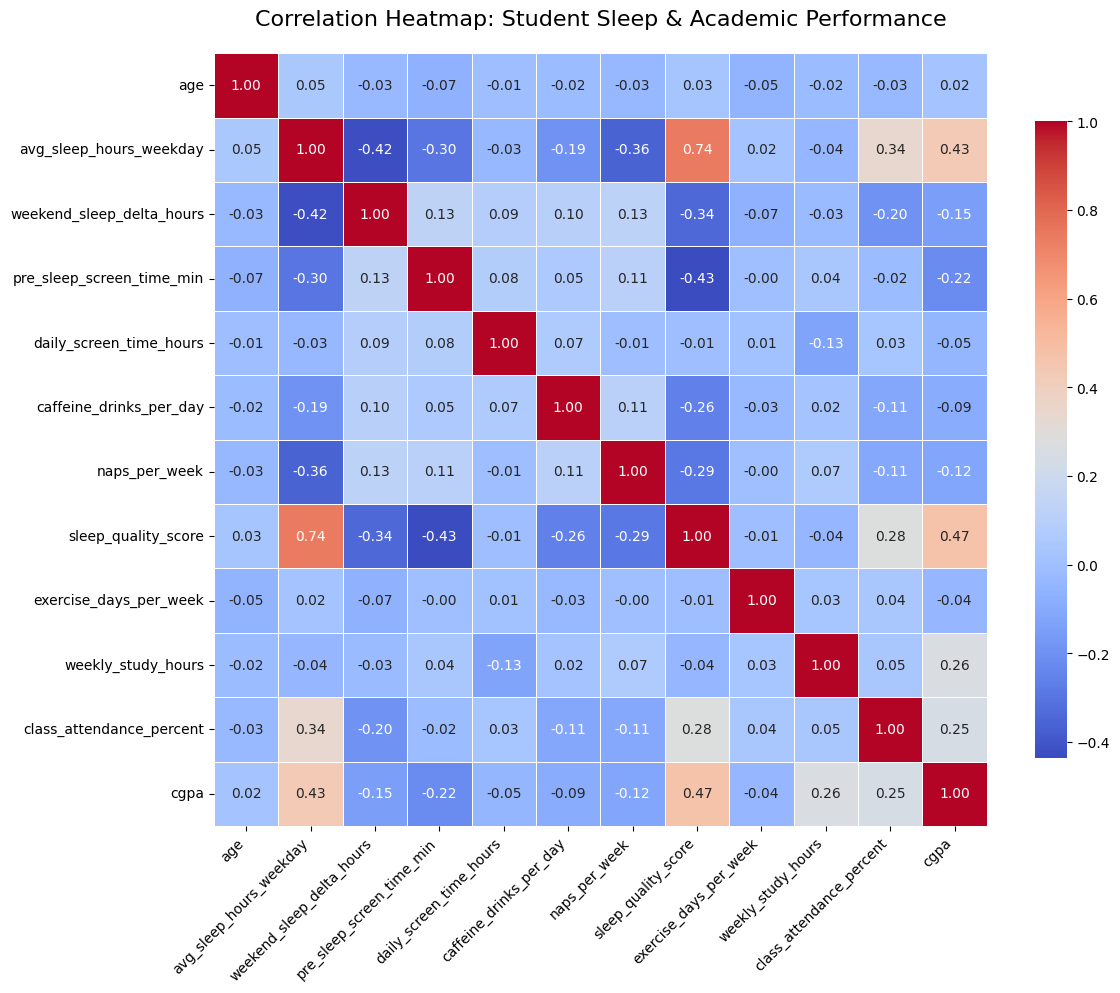

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select the normalized numeric columns
num_cols = [
    'age', 'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours',
    'pre_sleep_screen_time_min', 'daily_screen_time_hours',
    'caffeine_drinks_per_day', 'naps_per_week', 'sleep_quality_score',
    'exercise_days_per_week', 'weekly_study_hours',
    'class_attendance_percent', 'cgpa'
]

# 2. Compute the Pearson correlation matrix
corr_matrix = df_normalized[num_cols].corr()

# 3. Set up the matplotlib figure size
plt.figure(figsize=(12, 10))

# 4. Generate a custom diverging colormap (coolwarm or blues)
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# 5. Draw the heatmap with annotations
sns.heatmap(
    corr_matrix,
    annot=True,          # Show correlation values inside cells
    fmt=".2f",           # Format values to 2 decimal places
    cmap='coolwarm',     # Color gradient representing positive/negative links
    linewidths=0.5,      # Add tiny borders between squares
    square=True,         # Make cells perfectly square
    cbar_kws={"shrink": .8} # Shrink the color bar scale slightly
)

# 6. Adjust titles and display
plt.title('Correlation Heatmap: Student Sleep & Academic Performance', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define your features (X) and target variable (y)
features = ['sleep_quality_score', 'avg_sleep_hours_weekday', 'weekly_study_hours', 'class_attendance_percent']
target = 'cgpa'

X = df_normalized[features]
y = df_normalized[target]

# 2. Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Make predictions on the test dataset
y_pred = model.predict(X_test)

# 5. Evaluate the model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Performance ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared Score (R²): {r2:.4f}\n")

# 6. Display the impact (Coefficients) of each feature
print("--- Feature Impacts on CGPA ---")
coefficients = pd.DataFrame({'Feature': features, 'Coefficient Impact': model.coef_})
print(coefficients.sort_values(by='Coefficient Impact', ascending=False).to_string(index=False))


--- Model Performance ---
Root Mean Squared Error (RMSE): 0.1315
R-squared Score (R²): 0.4003

--- Feature Impacts on CGPA ---
                 Feature  Coefficient Impact
      weekly_study_hours            0.546453
     sleep_quality_score            0.196438
 avg_sleep_hours_weekday            0.181422
class_attendance_percent            0.069113


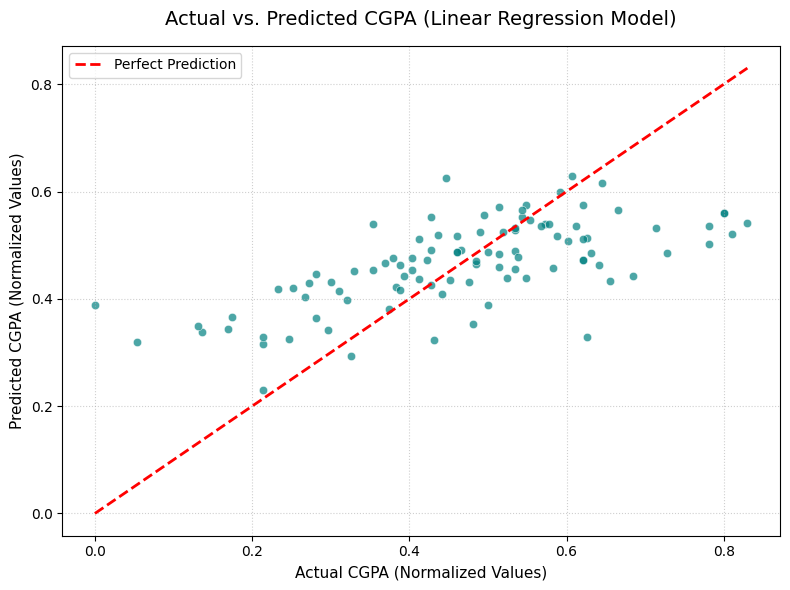

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting dimensions
plt.figure(figsize=(8, 6))

# Generate a scatter plot comparing real values to predictions
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='teal', edgecolor='w')

# Overlay a diagonal line representing 100% accurate predictions
max_val = max(max(y_test), max(y_pred))
min_val = min(min(y_test), min(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

# Titles and layout refinements
plt.title('Actual vs. Predicted CGPA (Linear Regression Model)', fontsize=14, pad=15)
plt.xlabel('Actual CGPA (Normalized Values)', fontsize=11)
plt.ylabel('Predicted CGPA (Normalized Values)', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
